In [14]:
import sys
from pathlib import Path
import pandas as pd

# project root = the folder that contains `src`, wherever the kernel was started
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt

from src.data.loader import load_cub, class_names
from src.data.prepare import prepare_splits
from src.data.loaders import build_dataloaders
from src.models.factory import build_classifier

## 1. Data

`load_cub` downloads (first run) or reads the cached CUB train and test splits. `prepare_splits` cleans the captions and carves the stratified validation set out of train. `build_dataloaders` wraps each split: train is augmented and shuffled, validation and test only get the deterministic resize and center crop.

In [15]:
raw = load_cub()  # default Hugging Face cache; pass cache_dir="data/hf_cache" to use the project folder
data = prepare_splits(raw["train"], raw["test"], val_fraction=0.15, seed=42)
print(data)

DatasetDict({
    train: Dataset({
        features: ['image', 'description', 'label', 'file_name', 'id', 'captions'],
        num_rows: 5094
    })
    validation: Dataset({
        features: ['image', 'description', 'label', 'file_name', 'id', 'captions'],
        num_rows: 900
    })
    test: Dataset({
        features: ['image', 'description', 'label', 'file_name', 'id', 'captions'],
        num_rows: 5794
    })
})


In [16]:
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

loaders = build_dataloaders(data, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, seed=SEED)
species = class_names(data["train"])

for name, loader in loaders.items():
    print(f"{name:10s} {len(loader.dataset):5d} images, {len(loader):3d} batches of {BATCH_SIZE}")
print("species:", len(species))

train       5094 images, 160 batches of 32
validation   900 images,  29 batches of 32
test        5794 images, 182 batches of 32
species: 200


In [17]:
images, labels = next(iter(loaders["train"]))
print("images:", tuple(images.shape), images.dtype)
print("labels:", tuple(labels.shape), labels.dtype, "| first five:", [species[i] for i in labels[:5]])

images: (32, 3, 224, 224) torch.float32
labels: (32,) torch.int64 | first five: ['Philadelphia Vireo', 'Gray Catbird', 'Black and white Warbler', 'Florida Jay', 'White Pelican']


In [18]:
model = build_classifier()

In [19]:
from torchinfo import summary

summary(
    model,
    input_size=(BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE),
    col_names=("input_size", "output_size", "num_params", "kernel_size"),
    depth=3,
    col_width=18,
)

Layer (type:depth-idx)                        Input Shape        Output Shape       Param #            Kernel Shape
BirdClassifier                                [32, 3, 224, 224]  [32, 200]          --                 --
├─ScratchEncoder: 1-1                         [32, 3, 224, 224]  [32, 32, 112, 112] --                 --
│    └─Sequential: 2-1                        [32, 3, 224, 224]  [32, 32, 112, 112] --                 --
│    │    └─Conv2d: 3-1                       [32, 3, 224, 224]  [32, 32, 112, 112] 864                [3, 3]
│    │    └─BatchNorm2d: 3-2                  [32, 32, 112, 112] [32, 32, 112, 112] 64                 --
│    │    └─ReLU: 3-3                         [32, 32, 112, 112] [32, 32, 112, 112] --                 --
│    └─ModuleList: 2-2                        --                 --                 --                 --
│    │    └─ResidualBlock: 3-4                [32, 32, 112, 112] [32, 64, 56, 56]   57,728             --
│    │    └─ResidualBlock: 3-5  

## 2. Training setup

Adam optimizer and cross-entropy loss. The loss takes raw logits, so the model has no softmax layer.

In [ ]:
import numpy as np
from torch import nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

LR = 1e-3
EPOCHS = 10

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

torch.manual_seed(SEED)  # same starting weights every run
model = build_classifier().to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [ ]:
# Use the same training/evaluation utilities as transfer learning and tuning.
# fit() automatically saves the best weights; no notebook-specific saving code.
from src.training.trainer import fit
from src.evaluation.classification import evaluate


## 3. Train

Every epoch: one pass over train, then one evaluation on validation. The weights of the epoch with the best validation accuracy are kept. Test is not touched until the end.

In [ ]:
run_config = {
    "name": "scratch_cnn_notebook", "encoder": "scratch", "freeze": False,
    "dropout": model.dropout.p, "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS, "seed": SEED,
    "lr": LR, "epochs": EPOCHS, "optimizer": "adam", "weight_decay": 0.0,
}
trained = fit(model, loaders, loss_fn, optimizer, device, EPOCHS,
              run_config=run_config, class_labels=species)
history = trained["history"]
best_state = trained["best_state"]
best_epoch = trained["best_epoch"]
best_val_accuracy = trained["best_val_accuracy"]
print(f"best validation accuracy {best_val_accuracy:.3f} at epoch {best_epoch}")
print("checkpoint:", trained["checkpoint_path"])


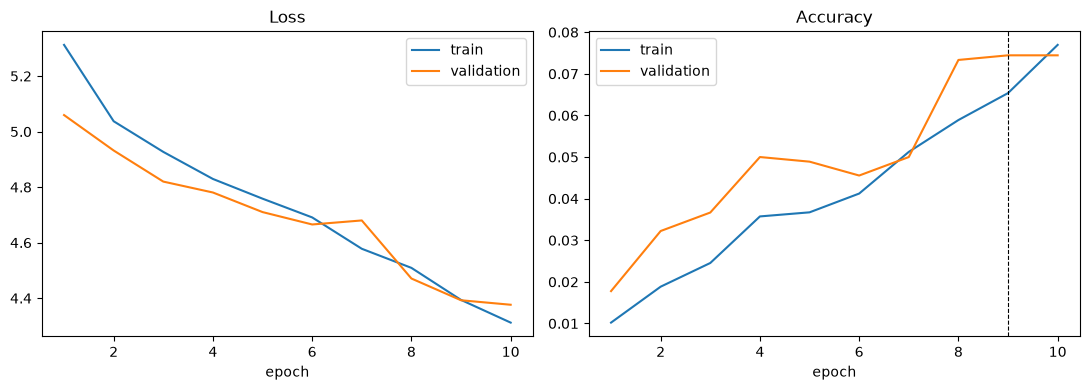

In [23]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs, [h["train_loss"] for h in history], label="train")
axes[0].plot(epochs, [h["val_loss"] for h in history], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()

axes[1].plot(epochs, [h["train_accuracy"] for h in history], label="train")
axes[1].plot(epochs, [h["val_accuracy"] for h in history], label="validation")
axes[1].axvline(best_epoch, ls="--", c="k", lw=0.8)
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Evaluate

The best-validation weights are loaded, then validation and test are evaluated once each.

In [24]:
model.load_state_dict(best_state)

rows = {}
for name in ("validation", "test"):
    result = evaluate(model, loaders[name], loss_fn, device)
    labels, predictions = result["labels"], result["predictions"]
    rows[name] = {
        "loss": result["loss"],
        "accuracy": accuracy_score(labels, predictions),
        "top-5 accuracy": result["top5_accuracy"],
        "precision (macro)": precision_score(labels, predictions, average="macro", zero_division=0),
        "recall (macro)": recall_score(labels, predictions, average="macro", zero_division=0),
        "F1 (macro)": f1_score(labels, predictions, average="macro", zero_division=0),
    }

pd.DataFrame(rows).round(4)

,validation,test
loss,4.3926,4.4010
accuracy,0.0744,0.0671
top-5 accuracy,0.2267,0.2263
precision (macro),0.0574,0.0654
recall (macro),0.0745,0.0684
F1 (macro),0.0504,0.0507
